In [82]:
# 匯入套件
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
from matplotlib import animation
from IPython.display import HTML

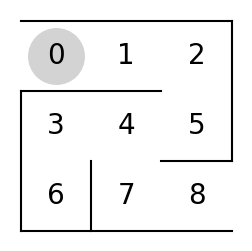

In [83]:
# 製作迷宮
fig = plt.figure(figsize=(3, 3))

# 製作牆壁
plt.plot([0, 3], [3, 3], color='k')
plt.plot([0, 3], [0, 0], color='k')
plt.plot([0, 0], [0, 2], color='k')
plt.plot([3, 3], [1, 3], color='k')
plt.plot([0, 2], [2, 2], color='k')
plt.plot([2, 3], [1, 1], color='k')
plt.plot([1, 1], [0, 1], color='k')

# 製作編號
for i in range(3):
    for j in range(3):
        plt.text(0.5+i, 2.5-j, str(i+j*3), size=20, ha='center', va='center')

# 製作當前位置的圓圈
circle, = plt.plot([0.5], [2.5], marker='o', color='#d3d3d3', markersize=40)

# 隱藏繪圖區的軸刻度與邊框
plt.tick_params(axis='both', which='both', bottom = False, top= False,
        labelbottom=False, right=False, left=False, labelleft=False)
plt.box(False)

**以下請根據以上的迷宮圖樣自行定義theta值**

In [84]:
# 準備參數 θ
#[上,右,下,左]
theta_0 = np.array([
    [np.nan, 1, np.nan, np.nan],  # 状態0: 上X,右O,下X,左X
    [np.nan, 1, np.nan, 1],       # 状態1: 上と左に壁
    [np.nan, np.nan, 1, 1],       # 状態2: 上と右に壁
    [np.nan, 1, 1, np.nan],  # 状態3: 上と左と右に壁
    [np.nan, 1, 1, 1],       # 状態4: 左と右に壁
    [1, np.nan, np.nan, 1],  # 状態5: 下と左と右に壁
    [1, np.nan, np.nan, np.nan],       # 状態6: 下と左に壁
    [1, 1, np.nan, np.nan],            # 状態7: 下に壁
    [np.nan, np.nan, np.nan, 1]        # 状態8: 下と右に壁
])



In [85]:
# 定義get_pi()函式
def get_pi(theta):
    # 利用 softmax 進行轉換
    [m, n] = theta.shape
    pi = np.zeros((m, n))
    for i in range(0, m):
        pi[i, :] = theta[i, :] / np.nansum(theta[i, :])
    pi = np.nan_to_num(pi)    
    return pi

# 將參數 θ 轉換成機率的形式
pi_0 = get_pi(theta_0)
print(pi_0)

[[0.         1.         0.         0.        ]
 [0.         0.5        0.         0.5       ]
 [0.         0.         0.5        0.5       ]
 [0.         0.5        0.5        0.        ]
 [0.         0.33333333 0.33333333 0.33333333]
 [0.5        0.         0.         0.5       ]
 [1.         0.         0.         0.        ]
 [0.5        0.5        0.         0.        ]
 [0.         0.         0.         1.        ]]


In [86]:
# 設定初始的動作價值函數表
[a, b] = theta_0.shape
Q = np.random.rand(a, b) * theta_0
print(Q)

[[       nan 0.08033123        nan        nan]
 [       nan 0.14684714        nan 0.4334328 ]
 [       nan        nan 0.60481874 0.96939309]
 [       nan 0.34205036 0.89821908        nan]
 [       nan 0.08551944 0.50253272 0.24911248]
 [0.057163          nan        nan 0.99910695]
 [0.41131219        nan        nan        nan]
 [0.8110387  0.6478075         nan        nan]
 [       nan        nan        nan 0.60212856]]


In [87]:
# 根據動作取得下一個狀態
def get_s_next(s, a):
    if a == 0: # 上
        return s - 3
    elif a == 1: # 右
        return s + 1
    elif a == 2: # 下
        return s + 3
    elif a == 3: # 左
        return s - 1

In [88]:
# 隨機或根據動作價值函數式選擇動作
def get_a(s, Q, epsilon, pi_0):
    if np.random.rand() < epsilon:
        # 依機率分布隨機選擇動作
        return np.random.choice([0, 1, 2, 3], p=pi_0[s])
    else:
        # 根據動作價值函數式選擇動作
        return np.nanargmax(Q[s])

**以下的學習率(alpha)和折價因子(gamma)如果有更改請在報告中提及**

In [89]:
# 利用 Q Learning更新動作價值函式
def q_learning(s, a, r, s_next, a_next, Q):
    alpha = 0.1 # 學習率
    gamma = 0.9 # 折價因子
    
    if s_next == 8:
        Q[s, a] = Q[s, a] + alpha * (r - Q[s, a]) #已經抵達終點，所以沒有下一步
    else:
        Q[s, a] = Q[s, a] + alpha * (r + gamma * np.nanmax(Q[s_next, :]) - Q[s, a]) #Q-learning演算法
    return Q

In [90]:
# 執行1回合
def play(Q, epsilon, pi):
    s = 0 # 狀態
    a = a_next = get_a(s, Q, epsilon, pi) # 下一步的動作
    s_a_history = [[0, np.nan]] # 狀態與動作的歷程資料

    # 持續循環直到回合結束
    while True:
        # 根據動作取得下一個狀態
        a = a_next
        s_next = get_s_next(s, a)

        # 更新歷程資料
        s_a_history[-1][1] = a
        s_a_history.append([s_next, np.nan])

        # 判斷是否結束
        if s_next == 8:
            r = 1
            a_next = np.nan
        else:
            r = 0
            # 根據動作價值函數取得動作
            a_next = get_a(s_next, Q, epsilon, pi)

        # 更新動作價值函數式
        Q = q_learning(s, a, r, s_next, a_next, Q)

        # 判斷是否結束
        if s_next == 8:
            break
        else:
            s = s_next

    # 傳回歷史資料及動作價值函數式
    return [s_a_history, Q]

**以下的episode的range請依照需求更改**

In [91]:
epsilon = 0.5  # ε的初始值(ε-greedy)

# 利用迴圈進行訓練
for episode in range(10):
    # 逐漸縮小 ε 的值
    epsilon = epsilon / 2

    # 執行1回合並取得歷史資料與動作價值函數
    [s_a_history, Q] = play(Q, epsilon, pi_0)
    
    print('回合: {}, 步數: {}'.format(episode, len(s_a_history)-1))

回合: 0, 步數: 34
回合: 1, 步數: 24
回合: 2, 步數: 8
回合: 3, 步數: 6
回合: 4, 步數: 6
回合: 5, 步數: 6
回合: 6, 步數: 6
回合: 7, 步數: 6
回合: 8, 步數: 6
回合: 9, 步數: 6


In [92]:
# 用來更新動畫的函式
def animate(i):
    state = s_a_history[i][0]
    circle.set_data((state % 3) + 0.5, 2.5 - int(state / 3))
    return circle

# 製作動畫
anim = animation.FuncAnimation(fig, animate, \
        frames=len(s_a_history), interval=200, repeat=False)
HTML(anim.to_jshtml())

/var/folders/nl/fjw7m0f13zv6gym6r4gjwy9w0000gn/T/ipykernel_12786/2580300153.py:4: MatplotlibDeprecationWarning: Setting data with a non sequence type is deprecated since 3.7 and will be remove two minor releases later
  circle.set_data((state % 3) + 0.5, 2.5 - int(state / 3))
